# METABRIC PCA and k-means negative-control grid

This companion to the [observed-data grid](PCA_KMeans_METABRIC_grid.ipynb) uses the [gene-wise shuffle control](../K-Means%20Negative%20Control.ipynb) for all 45 combinations of 20, 40, 60, 80, and 100 principal components and \(k=2,\ldots,10\).

Each of 100 replicates independently permutes every selected gene across its observed sample rows. The shuffle retains each gene’s values and missing positions while breaking cross-gene structure and sample-level alignment with PAM50. The clinical labels stay attached to the original sample IDs.

In [1]:
import os
from pathlib import Path
from time import perf_counter

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from joblib import Parallel, delayed, parallel_config
from scipy.spatial.distance import pdist, squareform
from sklearn.utils import check_random_state
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

DATA_DIR = Path("/Users/danielbility/Documents/brca/brca_metabric")
PC_COUNTS = (20, 40, 60, 80, 100)
K_VALUES = range(2, 11)
N_INIT = 20
BASE_SEED = 42
SILHOUETTE_SAMPLE_SIZE = 1000
N_RESAMPLES = 20
SUBSAMPLE_FRACTION = 0.80
N_SHUFFLES = 100
SHUFFLE_SEED = 707
N_JOBS = min(8, max(1, (os.cpu_count() or 1) - 2))

print(f"{len(PC_COUNTS) * len(K_VALUES)} settings × {N_SHUFFLES} shuffles  •  {N_JOBS} parallel workers")
print(f"NumPy {np.__version__}  •  pandas {pd.__version__}  •  "
      f"scikit-learn {sklearn.__version__}  •  Matplotlib {mpl.__version__}")

45 settings × 100 shuffles  •  8 parallel workers
NumPy 2.3.5  •  pandas 2.2.3  •  scikit-learn 1.9.1  •  Matplotlib 3.11.2


## Load expression data and align subtype labels

Sydney used mRNA expression z-scores relative to diploid samples. Duplicate gene symbols are averaged, and clinical labels are aligned to the expression matrix by sample ID. The five standard PAM50 groups are mapped from `CLAUDIN_SUBTYPE` for the NMI calculation. All expression samples enter clustering, silhouette, and stability.

In [2]:
expression_by_gene = pd.read_csv(
    DATA_DIR / "data_mrna_illumina_microarray_zscores_ref_diploid_samples.txt",
    sep="\t",
    index_col="Hugo_Symbol",
)
expression = (
    expression_by_gene.drop(columns="Entrez_Gene_Id", errors="ignore")
    .groupby(level=0).mean()
    .T.rename_axis("SAMPLE_ID")
)
del expression_by_gene

patients = pd.read_csv(
    DATA_DIR / "data_clinical_patient.txt",
    sep="\t",
    comment="#",
    usecols=["PATIENT_ID", "CLAUDIN_SUBTYPE"],
)
samples = pd.read_csv(
    DATA_DIR / "data_clinical_sample.txt",
    sep="\t",
    comment="#",
    usecols=["PATIENT_ID", "SAMPLE_ID"],
)
subtypes_by_sample = (
    patients.merge(samples, on="PATIENT_ID", validate="one_to_many")
    .set_index("SAMPLE_ID", verify_integrity=True)["CLAUDIN_SUBTYPE"]
)
raw_subtypes = subtypes_by_sample.reindex(expression.index).astype("string").str.strip()

pam50_map = {
    "LUMA": "Luminal A",
    "LUMINAL A": "Luminal A",
    "LUMB": "Luminal B",
    "LUMINAL B": "Luminal B",
    "HER2": "HER2-enriched",
    "HER2-ENRICHED": "HER2-enriched",
    "HER2 ENRICHED": "HER2-enriched",
    "BASAL": "Basal-like",
    "BASAL-LIKE": "Basal-like",
    "NORMAL": "Normal-like",
    "NORMAL-LIKE": "Normal-like",
}

pam50_labels = raw_subtypes.str.upper().map(pam50_map)
known_pam50 = pam50_labels.notna().to_numpy()
pam50_reference = pam50_labels.to_numpy(dtype=str, na_value="")[known_pam50]

print(f"Expression matrix  {expression.shape[0]:,} samples × {expression.shape[1]:,} genes")
print(f"Samples included in NMI  {known_pam50.sum():,} of {len(known_pam50):,}")
display(pam50_labels.fillna("Other or missing").value_counts().rename("Samples").to_frame())

Expression matrix  1,980 samples × 20,385 genes
Samples included in NMI  1,756 of 1,980


,Samples
CLAUDIN_SUBTYPE,
Luminal A,700
Luminal B,475
HER2-enriched,224
Other or missing,224
Basal-like,209
Normal-like,148


## Select expression genes

Apply Sydney’s missingness, variance, and median absolute deviation filters. Keeping the same 2,000 genes across shuffles gives the same selection as rerunning the filter, since the shuffle preserves each gene's marginal distribution and missingness.

In [3]:
import warnings
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

# Gene selection settings
MAX_GENE_MISSING = 0.10   # Exclude genes missing in more than 10% of samples
N_TOP_MAD_GENES = 2000    # Keep up to 2,000 genes with the highest MAD


def nan_mad(A):
    """Calculate each gene's median absolute deviation, ignoring missing values."""
    A = np.asarray(A, dtype=float)
    out = np.empty(A.shape[1])
    has_nan = np.isnan(A).any(axis=0)

    full = A[:, ~has_nan]
    out[~has_nan] = np.median(
        np.abs(full - np.median(full, axis=0)),
        axis=0
    )

    if has_nan.any():
        part = A[:, has_nan]
        out[has_nan] = np.nanmedian(
            np.abs(part - np.nanmedian(part, axis=0)),
            axis=0
        )

    return out


class MADGeneFilter(TransformerMixin, BaseEstimator):
    """Filter genes by missingness and variability, then keep the highest-MAD genes."""

    def __init__(self, max_missing=0.10, n_genes=2000):
        self.max_missing = max_missing
        self.n_genes = n_genes

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]

        # Step 1: exclude genes with too much missing data.
        passes_missing = np.isnan(X).mean(axis=0) <= self.max_missing

        # Step 2: exclude genes with no variation.
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=RuntimeWarning)
            spread = np.nanmax(X, axis=0) - np.nanmin(X, axis=0)

        passes_variance = passes_missing & (spread > 0)

        # Step 3: rank remaining genes by median absolute deviation.
        self.mad_ = np.full(X.shape[1], -np.inf)
        self.mad_[passes_variance] = nan_mad(X[:, passes_variance])
        ranking = np.argsort(-self.mad_, kind="stable")

        # Step 4: keep up to the requested number of genes.
        n_keep = min(self.n_genes, int(passes_variance.sum()))
        self.keep_idx_ = np.sort(ranking[:n_keep])

        self.n_genes_start_ = X.shape[1]
        self.n_after_step1_ = int(passes_missing.sum())
        self.n_after_step2_ = int(passes_variance.sum())
        self.mad_cutoff_ = (
            float(self.mad_[ranking[n_keep - 1]]) if n_keep else float("nan")
        )

        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.keep_idx_]

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            raise ValueError("Pass input gene names to get_feature_names_out().")
        return np.asarray(input_features, dtype=object)[self.keep_idx_]

gene_filter = MADGeneFilter(max_missing=MAX_GENE_MISSING, n_genes=N_TOP_MAD_GENES)
selected_expression = gene_filter.fit_transform(expression)

print(f"Genes at start  {gene_filter.n_genes_start_:,}")
print(f"After missingness filter  {gene_filter.n_after_step1_:,}")
print(f"After zero-variance filter  {gene_filter.n_after_step2_:,}")
print(f"Genes selected  {selected_expression.shape[1]:,}")

Genes at start  20,385
After missingness filter  20,385
After zero-variance filter  20,385
Genes selected  2,000


## Fit and score the observed and shuffled data

Each replicate refits median imputation, scaling, and randomized PCA once. The same PCA fit supplies nested prefixes of unwhitened scores for all five PC counts. Every full-data and subsample k-means fit uses 20 initializations.

- **Silhouette** uses Euclidean distances on the same seeded 1,000 rows as the observed grid.
- **Stability ARI** compares full-data k-means assignments with full-data predictions from each of 20 k-means fits on 80% subsamples. The score is their mean adjusted Rand index. Subsample rows are shared across settings and replicates, and preprocessing and PCA stay fixed within each replicate’s stability calculation.
- **NMI** compares full-data cluster assignments with the five standard PAM50 labels on the same 1,756 labeled samples, using arithmetic normalization.

In [4]:
def score_grid(expression_values, silhouette_rows, subsamples, subtype_mask, subtype_reference):
    with threadpool_limits(limits=1):
        imputed = SimpleImputer(strategy="median").fit_transform(expression_values)
        scaled = StandardScaler().fit_transform(imputed)
        pca = PCA(n_components=max(PC_COUNTS), svd_solver="randomized", random_state=0)
        pc_scores = pca.fit_transform(scaled)

        rows = []
        for n_pcs in PC_COUNTS:
            scores = np.ascontiguousarray(pc_scores[:, :n_pcs])
            distances = squareform(pdist(scores[silhouette_rows], metric="euclidean"))
            subsample_scores = [scores[indices] for indices in subsamples]
            for k in K_VALUES:
                base_model = KMeans(n_clusters=k, n_init=N_INIT, random_state=BASE_SEED)
                clusters = base_model.fit_predict(scores)
                stability = []
                for seed, training_scores in enumerate(subsample_scores):
                    refit = KMeans(n_clusters=k, n_init=N_INIT, random_state=seed)
                    refit.fit(training_scores)
                    stability.append(adjusted_rand_score(clusters, refit.predict(scores)))

                rows.append({
                    "n_pcs": n_pcs,
                    "k": k,
                    "Silhouette": silhouette_score(
                        distances, clusters[silhouette_rows], metric="precomputed"
                    ),
                    "Stability ARI": np.mean(stability),
                    "NMI": normalized_mutual_info_score(
                        subtype_reference, clusters[subtype_mask], average_method="arithmetic"
                    ),
                })
    return pd.DataFrame(rows).set_index(["n_pcs", "k"])


features = selected_expression
n_samples = len(features)
silhouette_rows = check_random_state(BASE_SEED).permutation(n_samples)[:SILHOUETTE_SAMPLE_SIZE]
rng = np.random.default_rng(0)
subsamples = [
    rng.choice(n_samples, int(SUBSAMPLE_FRACTION * n_samples), replace=False)
    for _ in range(N_RESAMPLES)
]
metric_names = ("Silhouette", "Stability ARI", "NMI")
expected_grid = pd.MultiIndex.from_product([PC_COUNTS, K_VALUES], names=["n_pcs", "k"])
score_args = (silhouette_rows, subsamples, known_pam50, pam50_reference)

observed = score_grid(features, *score_args)
assert observed.index.equals(expected_grid)
assert np.isfinite(observed.to_numpy()).all()
print(f"Scored all {len(observed)} observed settings")
display(observed.loc[[(20, 2), (20, 6), (100, 2)]].round(4))

Scored all 45 observed settings


Silhouette  Stability ARI     NMI
n_pcs k                                   
20    2      0.1584         0.9698  0.2832
      6      0.1073         0.7852  0.3355
100   2      0.1140         0.9706  0.2835

## Run 100 gene-wise shuffles

A shuffle supplies all 45 settings, so the comparisons across PC counts and \(k\) use the same shuffled data. The seed for each replicate is independent of the order in which parallel workers finish.

In [5]:
def shuffle_expression(values, rng):
    shuffled = np.empty_like(values)
    for feature in range(values.shape[1]):
        column = values[:, feature]
        observed_rows = ~np.isnan(column)
        if observed_rows.all():
            shuffled[:, feature] = rng.permutation(column)
        else:
            shuffled[:, feature] = np.nan
            shuffled[observed_rows, feature] = rng.permutation(column[observed_rows])
    return shuffled


def score_shuffle(replicate, expression_values, score_args):
    rng = np.random.default_rng(np.random.SeedSequence([SHUFFLE_SEED, replicate]))
    shuffled = shuffle_expression(expression_values, rng)
    if replicate == 1:
        np.testing.assert_array_equal(np.isnan(shuffled), np.isnan(expression_values))
        np.testing.assert_array_equal(np.sort(shuffled, axis=0), np.sort(expression_values, axis=0))
        assert not np.array_equal(shuffled, expression_values, equal_nan=True)
    return replicate, score_grid(shuffled, *score_args)


started = perf_counter()
null_runs = {}
with parallel_config(backend="loky", inner_max_num_threads=1):
    with Parallel(n_jobs=N_JOBS, return_as="generator_unordered") as pool:
        completed_runs = pool(
            delayed(score_shuffle)(replicate, features, score_args)
            for replicate in range(1, N_SHUFFLES + 1)
        )
        for completed, (replicate, scores) in enumerate(completed_runs, start=1):
            assert scores.index.equals(expected_grid)
            assert np.isfinite(scores.to_numpy()).all()
            null_runs[replicate] = scores
            if replicate == 1:
                print("Verified each gene’s values and missing positions in the first shuffle", flush=True)
            if completed == 1 or completed % 10 == 0 or completed == N_SHUFFLES:
                elapsed = perf_counter() - started
                print(f"Finished {completed:>3}/{N_SHUFFLES} shuffles  •  {elapsed:.1f} s", flush=True)

null_scores = pd.concat(null_runs, names=["shuffle"]).sort_index()
assert null_scores.index.is_unique
assert len(null_scores) == N_SHUFFLES * len(expected_grid)
print(f"Saved {len(null_scores):,} shuffled grid scores in memory")

Finished   1/100 shuffles  •  88.5 s


Verified each gene’s values and missing positions in the first shuffle


Finished  10/100 shuffles  •  186.9 s


Finished  20/100 shuffles  •  300.0 s


Finished  30/100 shuffles  •  427.4 s


Finished  40/100 shuffles  •  570.5 s


... (3 outputs left out)

Finished  80/100 shuffles  •  1297.4 s


Finished  90/100 shuffles  •  1639.1 s


Finished 100/100 shuffles  •  1746.3 s


Saved 4,500 shuffled grid scores in memory


## Compare observed scores with the null distributions

The central 95% interval is the 2.5th to the 97.5th percentile across the 100 shuffles. The upper-tail empirical p-value at each setting is the number of shuffled scores at least as high as the observed score plus one, divided by 101. The p-values are pointwise.

In [6]:
grouped_null = null_scores.groupby(level=["n_pcs", "k"])
summaries = {}
for metric in metric_names:
    quantiles = grouped_null[metric].quantile([0.025, 0.5, 0.975]).unstack()
    quantiles.columns = ["Null 2.5%", "Null median", "Null 97.5%"]
    actual = observed[metric].rename("Observed")
    exceedances = null_scores[metric].ge(
        actual.reindex(null_scores.index.droplevel("shuffle")).to_numpy()
    ).groupby(level=["n_pcs", "k"]).sum()
    summary = quantiles.join(actual)
    summary["Empirical p"] = (1 + exceedances) / (N_SHUFFLES + 1)
    summaries[metric] = summary

    print(metric)
    with pd.option_context("display.max_rows", len(summary)):
        display(summary[["Observed", "Null median", "Null 2.5%", "Null 97.5%", "Empirical p"]].round(4))

Silhouette


Observed  Null median  Null 2.5%  Null 97.5%  Empirical p
n_pcs k                                                            
20    2     0.1584       0.0344     0.0325      0.0361       0.0099
      3     0.1327       0.0314     0.0298      0.0331       0.0099
      4     0.1261       0.0312     0.0290      0.0330       0.0099
      5     0.1135       0.0309     0.0289      0.0330       0.0099
      6     0.1073       0.0311     0.0289      0.0331       0.0099
      7     0.1032       0.0317     0.0299      0.0335       0.0099
      8     0.1040       0.0319     0.0299      0.0338       0.0099
      9     0.0989       0.0322     0.0301      0.0337       0.0099
      10    0.0961       0.0321     0.0300      0.0343       0.0099
40    2     0.1352       0.0176     0.0166      0.0189       0.0099
      3     0.1114       0.0161     0.0150      0.0172       0.0099
      4     0.1054       0.0155     0.0144      0.0166       0.0099
      5     0.0939       0.0155     0.0138      0.0167       0.0099
      6     0.0835       0.0154     0.0140      0.0165       0.0099
      7     0.0824       0.0156     0.0140      0.0167       0.0099
      8     0.0836       0.0153     0.0141      0.0167       0.0099
      9     0.0783       0.0155     0.0142      0.0167       0.0099
      10    0.0816       0.0156     0.0130      0.0169       0.0099
60    2     0.1243       0.0120     0.0113      0.0128       0.0099
      3     0.1007       0.0109     0.0101      0.0115       0.0099
      4     0.0950       0.0106     0.0097      0.0112       0.0099
      5     0.0847       0.0104     0.0092      0.0110       0.0099
      6     0.0724       0.0103     0.0091      0.0112       0.0099
      7     0.0726       0.0103     0.0089      0.0113       0.0099
      8     0.0734       0.0101     0.0089      0.0111       0.0099
      9     0.0679       0.0100     0.0084      0.0113       0.0099
      10    0.0699       0.0100     0.0087      0.0114       0.0099
80    2     0.1181       0.0092     0.0087      0.0098       0.0099
      3     0.0944       0.0082     0.0075      0.0088       0.0099
      4     0.0898       0.0079     0.0069      0.0084       0.0099
      5     0.0798       0.0078     0.0069      0.0085       0.0099
      6     0.0692       0.0076     0.0066      0.0083       0.0099
      7     0.0668       0.0076     0.0065      0.0084       0.0099
      8     0.0677       0.0074     0.0060      0.0083       0.0099
      9     0.0617       0.0073     0.0063      0.0084       0.0099
      10    0.0600       0.0073     0.0058      0.0082       0.0099
100   2     0.1140       0.0074     0.0070      0.0079       0.0099
      3     0.0896       0.0067     0.0058      0.0072       0.0099
      4     0.0854       0.0063     0.0053      0.0069       0.0099
      5     0.0758       0.0062     0.0051      0.0067       0.0099
      6     0.0678       0.0059     0.0050      0.0067       0.0099
      7     0.0625       0.0060     0.0050      0.0068       0.0099
      8     0.0633       0.0059     0.0046      0.0066       0.0099
      9     0.0571       0.0056     0.0044      0.0064       0.0099
      10    0.0567       0.0056     0.0044      0.0064       0.0099

Stability ARI


Observed  Null median  Null 2.5%  Null 97.5%  Empirical p
n_pcs k                                                            
20    2     0.9698       0.0469     0.0155      0.1079       0.0099
      3     0.9636       0.0552     0.0336      0.0815       0.0099
      4     0.8548       0.0653     0.0472      0.0874       0.0099
      5     0.8414       0.0728     0.0537      0.0967       0.0099
      6     0.7852       0.0767     0.0604      0.0938       0.0099
      7     0.8515       0.0801     0.0639      0.0956       0.0099
      8     0.9187       0.0828     0.0705      0.0984       0.0099
      9     0.8265       0.0827     0.0734      0.0960       0.0099
      10    0.6839       0.0856     0.0759      0.1022       0.0099
40    2     0.9698       0.0278     0.0097      0.0590       0.0099
      3     0.9605       0.0306     0.0211      0.0445       0.0099
      4     0.8701       0.0320     0.0251      0.0450       0.0099
      5     0.8543       0.0339     0.0268      0.0425       0.0099
      6     0.7675       0.0364     0.0296      0.0453       0.0099
      7     0.8698       0.0383     0.0321      0.0452       0.0099
      8     0.9056       0.0385     0.0336      0.0446       0.0099
      9     0.8337       0.0397     0.0351      0.0464       0.0099
      10    0.6976       0.0401     0.0359      0.0460       0.0099
60    2     0.9687       0.0186     0.0083      0.0379       0.0099
      3     0.9593       0.0202     0.0146      0.0297       0.0099
      4     0.8552       0.0225     0.0178      0.0301       0.0099
      5     0.8381       0.0242     0.0203      0.0289       0.0099
      6     0.7790       0.0249     0.0206      0.0294       0.0099
      7     0.8683       0.0257     0.0218      0.0297       0.0099
      8     0.9075       0.0261     0.0231      0.0299       0.0099
      9     0.8105       0.0268     0.0233      0.0301       0.0099
      10    0.6660       0.0273     0.0240      0.0304       0.0099
80    2     0.9704       0.0159     0.0075      0.0290       0.0099
      3     0.9590       0.0168     0.0120      0.0238       0.0099
      4     0.8703       0.0177     0.0139      0.0229       0.0099
      5     0.8405       0.0190     0.0154      0.0226       0.0099
      6     0.7865       0.0195     0.0163      0.0229       0.0099
      7     0.8566       0.0197     0.0172      0.0229       0.0099
      8     0.9045       0.0206     0.0178      0.0242       0.0099
      9     0.7547       0.0208     0.0184      0.0233       0.0099
      10    0.6287       0.0209     0.0182      0.0235       0.0099
100   2     0.9706       0.0136     0.0062      0.0247       0.0099
      3     0.9602       0.0147     0.0102      0.0211       0.0099
      4     0.8767       0.0150     0.0114      0.0209       0.0099
      5     0.8642       0.0157     0.0124      0.0194       0.0099
      6     0.7466       0.0165     0.0138      0.0195       0.0099
      7     0.8628       0.0170     0.0147      0.0190       0.0099
      8     0.9055       0.0171     0.0146      0.0197       0.0099
      9     0.8009       0.0172     0.0153      0.0198       0.0099
      10    0.7103       0.0175     0.0152      0.0204       0.0099

NMI


Observed  Null median  Null 2.5%  Null 97.5%  Empirical p
n_pcs k                                                            
20    2     0.2832       0.0009     0.0001      0.0026       0.0099
      3     0.2630       0.0015     0.0007      0.0036       0.0099
      4     0.2486       0.0023     0.0011      0.0051       0.0099
      5     0.3061       0.0029     0.0013      0.0048       0.0099
      6     0.3355       0.0035     0.0017      0.0059       0.0099
      7     0.3263       0.0040     0.0022      0.0063       0.0099
      8     0.3195       0.0044     0.0027      0.0075       0.0099
      9     0.3049       0.0050     0.0027      0.0085       0.0099
      10    0.3006       0.0053     0.0037      0.0086       0.0099
40    2     0.2841       0.0010     0.0001      0.0027       0.0099
      3     0.2664       0.0016     0.0006      0.0042       0.0099
      4     0.2484       0.0024     0.0009      0.0046       0.0099
      5     0.3070       0.0029     0.0013      0.0052       0.0099
      6     0.3230       0.0036     0.0019      0.0057       0.0099
      7     0.3182       0.0038     0.0019      0.0073       0.0099
      8     0.3178       0.0043     0.0025      0.0071       0.0099
      9     0.3082       0.0050     0.0026      0.0073       0.0099
      10    0.3027       0.0056     0.0032      0.0079       0.0099
60    2     0.2837       0.0010     0.0002      0.0035       0.0099
      3     0.2650       0.0017     0.0004      0.0038       0.0099
      4     0.2490       0.0021     0.0008      0.0037       0.0099
      5     0.3069       0.0030     0.0015      0.0055       0.0099
      6     0.3133       0.0033     0.0017      0.0054       0.0099
      7     0.3199       0.0040     0.0021      0.0065       0.0099
      8     0.3170       0.0047     0.0024      0.0072       0.0099
      9     0.3155       0.0051     0.0029      0.0079       0.0099
      10    0.3144       0.0052     0.0033      0.0078       0.0099
80    2     0.2835       0.0010     0.0002      0.0024       0.0099
      3     0.2655       0.0016     0.0006      0.0038       0.0099
      4     0.2486       0.0025     0.0011      0.0041       0.0099
      5     0.3081       0.0029     0.0014      0.0056       0.0099
      6     0.3248       0.0034     0.0017      0.0056       0.0099
      7     0.3234       0.0037     0.0017      0.0066       0.0099
      8     0.3175       0.0046     0.0025      0.0074       0.0099
      9     0.3063       0.0049     0.0027      0.0078       0.0099
      10    0.3005       0.0053     0.0036      0.0081       0.0099
100   2     0.2835       0.0008     0.0001      0.0030       0.0099
      3     0.2638       0.0016     0.0006      0.0038       0.0099
      4     0.2486       0.0023     0.0009      0.0044       0.0099
      5     0.3065       0.0030     0.0014      0.0049       0.0099
      6     0.3305       0.0033     0.0018      0.0053       0.0099
      7     0.3234       0.0041     0.0022      0.0064       0.0099
      8     0.3174       0.0046     0.0025      0.0072       0.0099
      9     0.3129       0.0049     0.0033      0.0080       0.0099
      10    0.3062       0.0054     0.0032      0.0091       0.0099

## Shuffled scores across k

Each panel shows a measure. Lines trace the shuffled median across \(k\) for a fixed number of PCs. Shaded bands show the central 95% of shuffled scores at each setting.

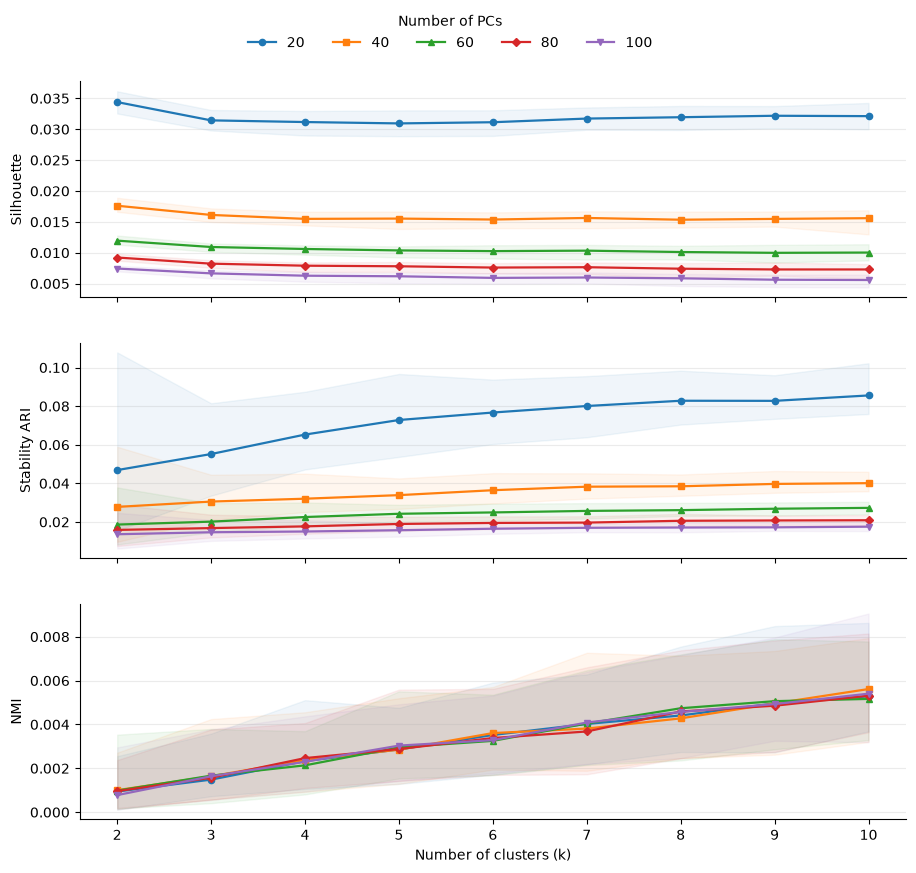

In [7]:
def plot_null_profiles(x_values, x_label, series_col, series_values, legend_title):
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(9.5, 9))
    colors = plt.get_cmap("tab10").colors
    markers = ("o", "s", "^", "D", "v", "P", "X", "<", ">")

    for ax, metric in zip(axes, metric_names):
        summary = summaries[metric]
        for value, color, marker in zip(series_values, colors, markers):
            profile = summary.xs(value, level=series_col).sort_index()
            x = profile.index.to_numpy()
            ax.fill_between(
                x, profile["Null 2.5%"], profile["Null 97.5%"], color=color, alpha=0.065
            )
            ax.plot(
                x, profile["Null median"], label=str(value),
                color=color, marker=marker, linewidth=1.6, markersize=4.5,
            )
        ax.set_ylabel(metric)
        ax.grid(axis="y", alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)

    axes[-1].set_xticks(list(x_values))
    axes[-1].set_xlabel(x_label)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels, title=legend_title, ncol=len(labels),
        loc="upper center", bbox_to_anchor=(0.5, 0.988), frameon=False,
    )
    fig.subplots_adjust(left=0.11, right=0.98, top=0.90, bottom=0.08, hspace=0.21)
    plt.show()


plot_null_profiles(
    x_values=K_VALUES, x_label="Number of clusters (k)",
    series_col="n_pcs", series_values=PC_COUNTS, legend_title="Number of PCs",
)

## Shuffled scores across PC counts

Each line fixes \(k\) while varying the number of PCs. Lines and bands summarize the same shuffles as above.

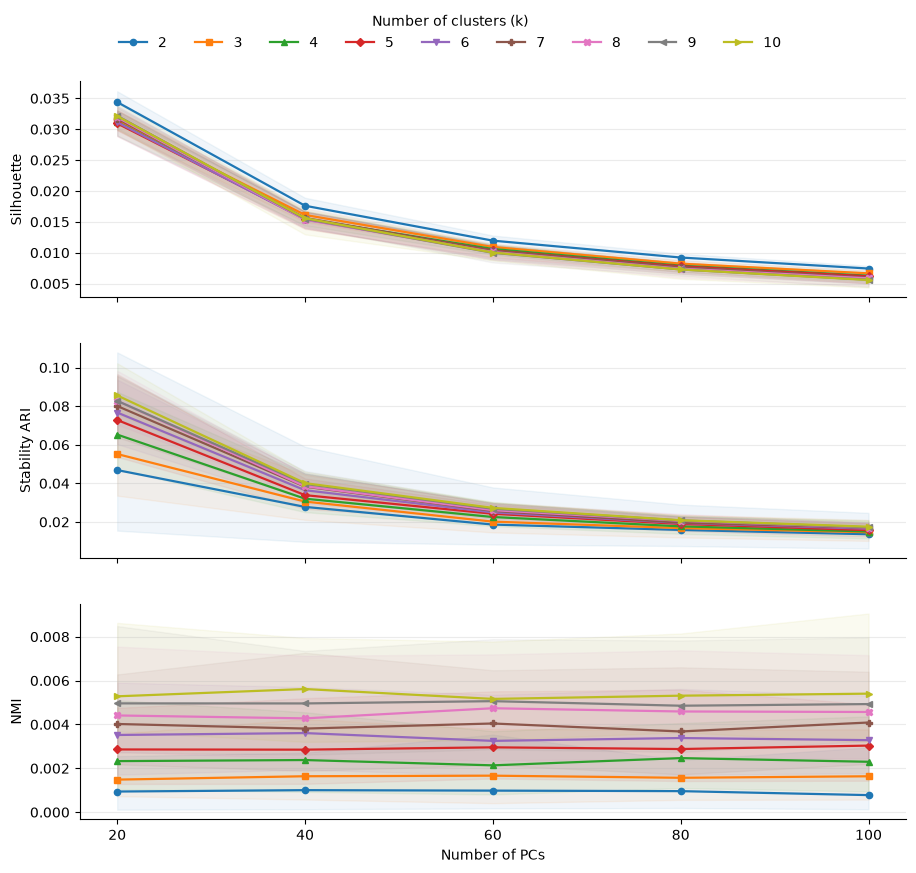

In [8]:
plot_null_profiles(
    x_values=PC_COUNTS, x_label="Number of PCs",
    series_col="k", series_values=K_VALUES, legend_title="Number of clusters (k)",
)

## How often did the observed scores exceed the shuffled range?

In [9]:
grid_overview = []
for metric, summary in summaries.items():
    grid_overview.append({
        "Measure": metric,
        "Observed above null 97.5%": int(summary["Observed"].gt(summary["Null 97.5%"]).sum()),
        "Settings": len(summary),
        "Minimum null median": summary["Null median"].min(),
        "Maximum null median": summary["Null median"].max(),
    })
display(pd.DataFrame(grid_overview).set_index("Measure").round(4))

,Observed above null 97.5%,Settings,Minimum null median,Maximum null median
Measure,,,,
Silhouette,45,45,0.0056,0.0344
Stability ARI,45,45,0.0136,0.0856
NMI,45,45,0.0008,0.0056
